In [1]:
import pandas as pd
df=pd.read_csv("tips.csv")

from sklearn.model_selection import train_test_split

X = df[["total_bill"]]
y = df["tip"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print(len(X_train))
print(len(X_test))
print(len(y_train))
print(len(y_test))

170
74
170
74


We use this 30% to see how the model evaluates new data. This helps with accuracy to ensure that the process is ensured when learning unfamiliar data.

In [2]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

print(model.coef_, model.intercept_)

[0.10889371] 0.8769576391532707


Each extra dollar of bill adds about 11 cents of tip.

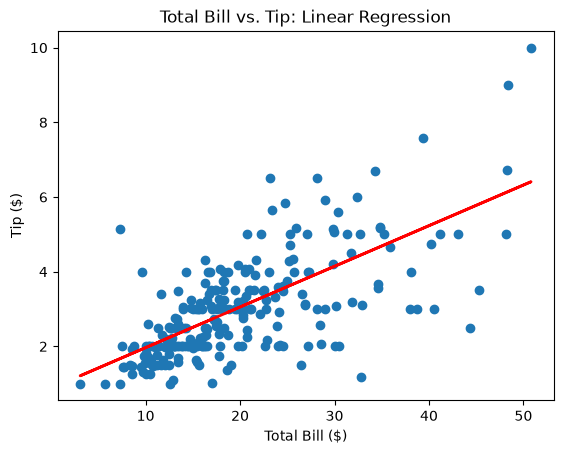

In [3]:
import matplotlib.pyplot as plt

y_pred = model.predict(X)

plt.scatter(df["total_bill"], df["tip"])

plt.plot(
    df["total_bill"],
    y_pred,
    color="red",
    linewidth=2,
    label="Fitted regression line"
)

plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.title("Total Bill vs. Tip: Linear Regression")
plt.show()

In [4]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
print(len(X))
print(len(X_train))

150
105


In [5]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

print(knn.score(X_test, y_test))

1.0


Decision Tree Test Accuracy: 1.0


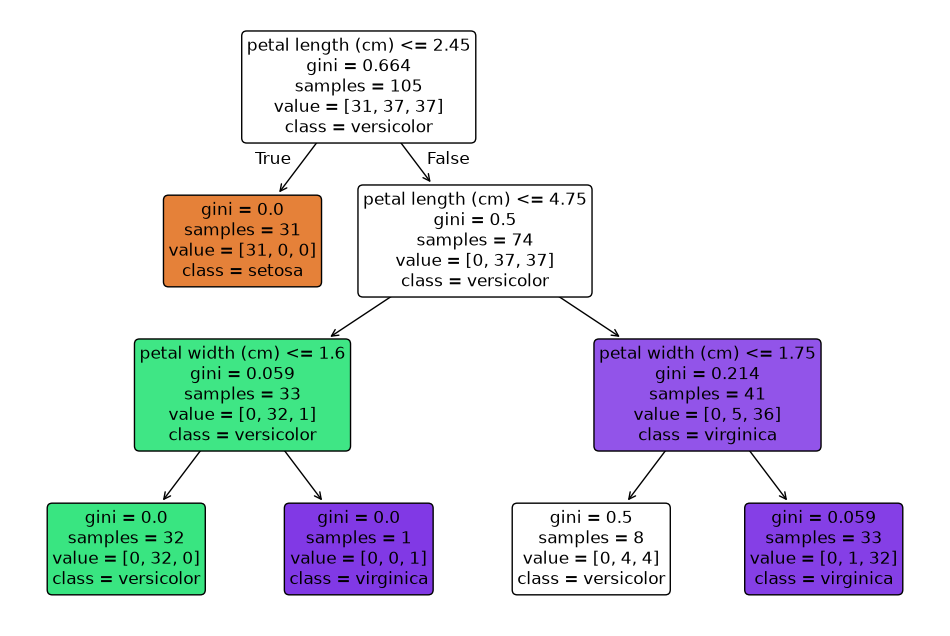

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

print("Decision Tree Test Accuracy:", tree.score(X_test, y_test))

plt.figure(figsize=(12, 8))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)
plt.show()

The decison tree initially checks if the petal is less than or greater than .8. Afterwards, it classifies the flower class base on the other data presented.

In [7]:
unlimited_tree = DecisionTreeClassifier()
unlimited_tree.fit(X_train, y_train)

scores = pd.DataFrame({
    "Model": ["Shallow tree", "Unlimited tree"],
    "Train score": [
        tree.score(X_train, y_train),
        unlimited_tree.score(X_train, y_train)
    ],
    "Test score": [
        tree.score(X_test, y_test),
        unlimited_tree.score(X_test, y_test)]})

scores

,Model,Train score,Test score
0,Shallow tree,0.952381,1.0
1,Unlimited tree,1.000000,1.0


This table shows that while the shallow tree has the test score is the same, the train score is not suggesting that the shallow tree is a better fit than the unlimited tree. 

In [8]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

predicted_class = tree.predict(new_flower)[0]
predicted_species = iris.target_names[predicted_class]

print("New flower measurements:")
print(new_flower.to_string(index=False))
print("\nPredicted species:", predicted_species)

New flower measurements:
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
               5.1               3.5                1.4               0.2

Predicted species: setosa


In this lab, the model was suggested to have 11 cents of extra tip for every extra dollar on the total bill. From the second half, the flower statistics I suggested was predicted to be a setosa. I would prefer to use kNN for a model because it is simpler and more straightfoward to use. However, the model will fail if there is a massive outlier in the results, such as if this sample was abnormal compared to all the other data. This would cause incorrect predictions which can be dangerous in some scenarios. If human height was used for this model instead of plants, there may have had been even more differences, considering gender and race, which can badly skew the analysis.

Repo Address: https://github.com/KyeSPu/cs82a-portfolio